# ONNX export and CPU benchmark

Exporting changes the runtime representation, not the trained weights. We verify the graph and compare outputs before measuring speed. The export accepts one preprocessed two-band 512×512 chip and returns raw water logits. Apply sigmoid, then the frozen threshold 0.55.

The FP32 check compares probabilities across all validation chips using absolute and relative tolerances 1e-4, with at most 0.01% binary mask disagreement. Both runtimes use four CPU threads. Timing covers warm in-memory forward passes only, excluding file loading, preprocessing, sigmoid, and mask creation. It is a local laptop benchmark, not a hosting latency guarantee.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))
# Set SEN1FLOODS11_ROOT to use a different local dataset location.
root = Path(os.environ.get("SEN1FLOODS11_ROOT", str(Path.home() / ".cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11")))
assert (root / "splits/flood_test_data.csv").is_file(), f"Dataset not found: {root}"
print("Dataset:", root)


Dataset: /Users/mac/.cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11


{
  "checkpoint_sha256": "a08d985b110fe8096efe571a2687d93decb680a826694c03ea8f4222d3e687bc",
  "onnx_sha256": "73fb31bbf88120a8f1e1cee20fd7c8b7f78add716a1954afaaa213f1e5bcdb08",
  "split_csv_sha256": "04999b82b93e393c32a54ac85b2bf8a18b671f7a6f43a9478b340e8a9b9647fb",
  "threshold": 0.55,
  "input_shape": [
    1,
    2,
    512,
    512
  ],
  "output": "raw water logits",
  "opset": 17,
  "dtype": "float32",
  "platform": "macOS-15.8.3-x86_64-i386-64bit",
  "cpu": "Intel(R) Core(TM) i7-8850H CPU @ 2.60GHz",
  "threads": 4,
  "provider": [
    "CPUExecutionProvider"
  ],
  "warmup_runs": 3,
  "repetitions": 20,
  "benchmark_chip": "Ghana_5079_S1Hand.tif",
  "timing_scope": "Warm in-memory forward pass only; excludes preprocessing, loading, sigmoid and mask creation",
  "environment": {
    "torch": "2.2.2",
    "onnx": "1.23.2",
    "onnxruntime": "1.23.2",
    "numpy": "1.26.4",
    "segmentation-models-pytorch": "0.6.0"
  },
  "bytes": {
    "pytorch_checkpoint": 97891199,
    "onnx_

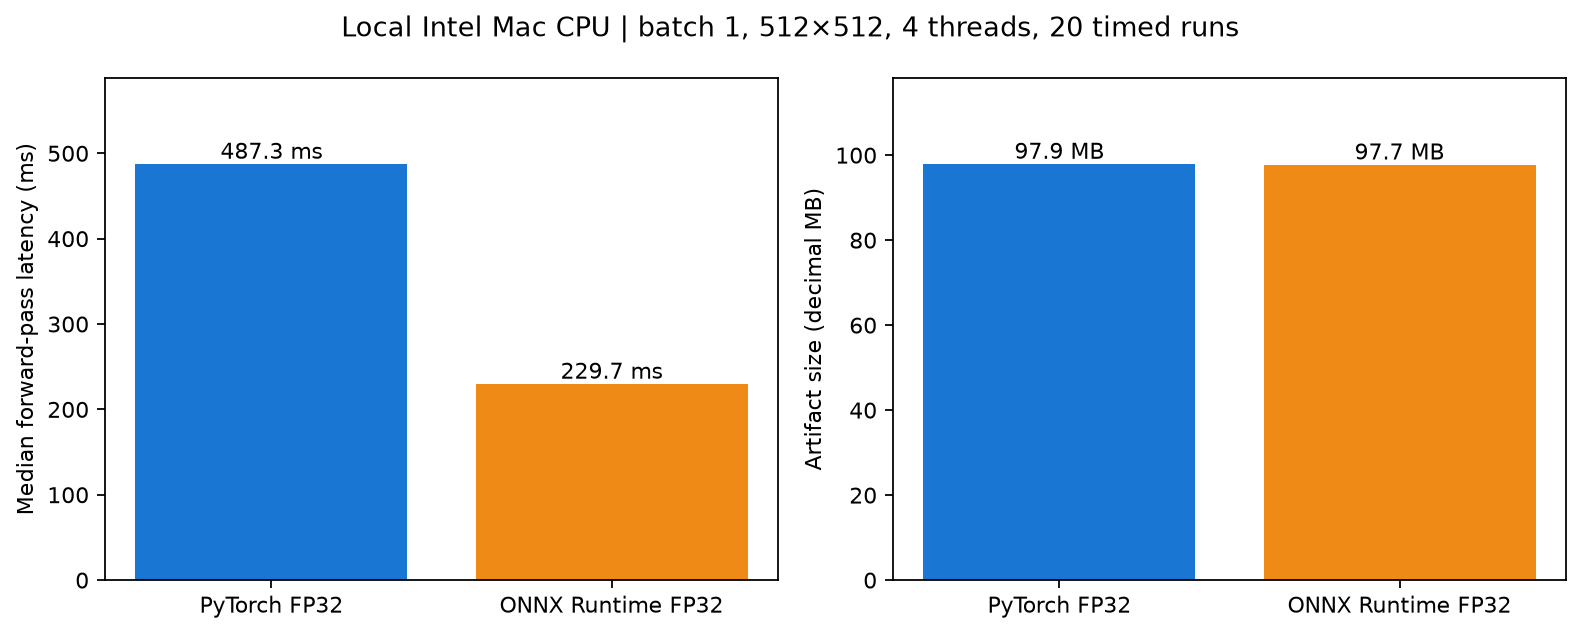

In [2]:
# To reproduce the export, choose a NEW output directory (existing exports are preserved).
# Run in a terminal from PROJECT:
# python -m floodrisk.deploy.export --root /path/to/sen1floods11 \
#   --checkpoint best.pt \
#   --config reports/m1-s1-kaggle-365653491/threshold_sweep/selected_config.json \
#   --output reports/m1-s1-kaggle-365653491/onnx_fp32

import json
from IPython.display import Image, display
out = PROJECT / "reports/m1-s1-kaggle-365653491/onnx_fp32"
report = json.loads((out / "benchmark.json").read_text())
assert report["parity"]["passed"]
print(json.dumps(report, indent=2))
display(Image(filename=str(out / "cpu_export_comparison.png")))


## Measured outcome

The export passes the predefined probability and mask checks across 89 validation chips. One binary pixel differs out of 23,330,816; pooled water IoU agrees to six decimal places. These are numerically close outputs rather than bitwise-identical outputs.

On the recorded Intel i7-8850H Mac, median forward-pass latency is **487 ms** for PyTorch and **230 ms** for ONNX Runtime (approximately **2.1×** faster). Both use four CPU threads and batch size one. The ONNX FP32 file is **97.7 MB**, so this is not a substantial compression result. These timings exclude data loading, preprocessing, sigmoid, and mask creation, and do not establish hosted or end-to-end latency. INT8 quantisation remains a separate future experiment.